#Project Overview

# Twitter Named Entity Recognition (NER) using BERT + CRF

## Project Overview

Named Entity Recognition (NER) is a Natural Language Processing (NLP) task that identifies and classifies named entities in text into categories such as person, company, geographical location, product, movie, and music artist.

In this project, I developed a sequence-labeling model to identify named entities in Twitter text using **BERT (Bidirectional Encoder Representations from Transformers)** combined with a **Conditional Random Field (CRF)** layer.

Twitter text presents challenges for NER because of informal language, unconventional spelling, abbreviations, noisy text, and domain-specific entity mentions.

## Project Objectives

- Build a BERT-based model for token-level entity classification.
- Integrate a CRF layer to model dependencies between consecutive entity labels.
- Process BIO-formatted labels (`B-`, `I-`, and `O`) and correctly align labels with BERT subword tokens.
- Evaluate model performance using precision, recall, F1-score, and entity-level classification reports.
- Analyze model errors and investigate whether oversampling minority-class examples improves performance.
- Build a reusable inference pipeline to predict entity labels and extract complete entities from new text.

## Approach

The project follows an end-to-end NLP workflow:

1. Explore the dataset and analyze entity-label distributions.
2. Preprocess the data and split the training data into training and validation sets.
3. Tokenize the text using the pretrained `bert-base-uncased` tokenizer and align BIO labels with subword tokens.
4. Train and evaluate a BERT token-classification baseline.
5. Implement and train a BERT + CRF model.
6. Evaluate performance on held-out test data and analyze errors across entity categories.
7. Implement reusable inference functions for word-level predictions and entity extraction.

## Final Results

| Metric | Result |
|---|---:|
| Validation F1-score | 64.71% |
| Test F1-score | 47.31% |

The model performed better on the validation set than on the held-out test set, indicating a generalization gap. Error analysis highlighted substantial variation across entity categories, particularly for less frequent or challenging entity types.

The oversampling experiment achieved a validation F1-score of 61.44%, below the original model's 64.71%. Therefore, the original BERT + CRF model was retained as the final candidate.

## Key Learning Outcomes

- Transformer-based token classification and contextual representations.
- BIO sequence labeling and subword-label alignment.
- CRF-based sequence decoding.
- Entity-level model evaluation and error analysis.
- Experimental comparison and reproducible model selection.
- Building an inference pipeline for a trained NLP model.

## Limitations

The test F1-score indicates that the model still struggles to generalize across the dataset. Potential future work includes investigating domain-specific pretrained models, improving rare-entity recognition, and conducting more targeted error-driven experiments.

In [ ]:
from transformers import AutoTokenizer

In [ ]:
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
sentence = "I am playing football."

tokens = tokenizer.tokenize(sentence)

print(tokens)

['i', 'am', 'playing', 'football', '.']


In [ ]:
sentence = "unaffable"

tokens = tokenizer.tokenize(sentence)

print(tokens)

['una', '##ffa', '##ble']


In [ ]:
sentence = "Harry Potter lives in London."

encoded = tokenizer(
    sentence,
    add_special_tokens=True
)

print("Tokens:", tokenizer.convert_ids_to_tokens(
    encoded["input_ids"]
))

print("Input IDs:", encoded["input_ids"])

Tokens: ['[CLS]', 'harry', 'potter', 'lives', 'in', 'london', '.', '[SEP]']
Input IDs: [101, 4302, 10693, 3268, 1999, 2414, 1012, 102]


In [ ]:
print("Attention mask:", encoded["attention_mask"])

Attention mask: [1, 1, 1, 1, 1, 1, 1, 1]


In [ ]:
batch = tokenizer(
    [
        "Harry lives in London.",
        "I love natural."
    ],
    padding=True,
    return_tensors="pt"
)

print("Input IDs:")
print(batch["input_ids"])

for enc in batch["input_ids"]:
    print("Tokens :",tokenizer.convert_ids_to_tokens(enc))

print("\nAttention masks:")
print(batch["attention_mask"])

Input IDs:
tensor([[ 101, 4302, 3268, 1999, 2414, 1012,  102],
        [ 101, 1045, 2293, 3019, 1012,  102,    0]])
Tokens : ['[CLS]', 'harry', 'lives', 'in', 'london', '.', '[SEP]']
Tokens : ['[CLS]', 'i', 'love', 'natural', '.', '[SEP]', '[PAD]']

Attention masks:
tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 0]])


#NER case study

##Dataset and Exploratory Analysis

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
TRAIN_PATH = "drive/MyDrive/datasets_scaler/train.txt.conll"
TEST_PATH = "drive/MyDrive/datasets_scaler/test.txt.conll"

In [ ]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

np.random.seed(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# TRAIN_PATH = Path("/content/wnut 16.txt.conll")
# TEST_PATH = Path("/content/wnut 16test.txt.conll")

# print("Training file exists:", TRAIN_PATH.exists())
# print("Test file exists:", TEST_PATH.exists())

In [ ]:
def read_conll(file_path):
    sentences = []
    current_sentence = []

    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            if not line:
                if current_sentence:
                    sentences.append(current_sentence)
                    current_sentence = []
                continue

            parts = line.rsplit(maxsplit=1)

            if len(parts) != 2:
                raise ValueError(
                    f"Malformed CoNLL line: {line!r}"
                )

            token, tag = parts
            current_sentence.append((token, tag))

    if current_sentence:
        sentences.append(current_sentence)

    return sentences

In [ ]:
train_sentences = read_conll(TRAIN_PATH)
test_sentences = read_conll(TEST_PATH)

print("Training sentences:", len(train_sentences))
print("Test sentences:", len(test_sentences))

print("\nFirst training sentence:")
print(train_sentences[0])

Training sentences: 2394
Test sentences: 3850

First training sentence:
[('@SammieLynnsMom', 'O'), ('@tg10781', 'O'), ('they', 'O'), ('will', 'O'), ('be', 'O'), ('all', 'O'), ('done', 'O'), ('by', 'O'), ('Sunday', 'O'), ('trust', 'O'), ('me', 'O'), ('*wink*', 'O')]


In [ ]:
for i, sentence in enumerate(train_sentences[:3], start=1):
    print(f"\nSentence {i}")

    for token, tag in sentence:
        print(f"{token:<20} {tag}")


Sentence 1
@SammieLynnsMom      O
@tg10781             O
they                 O
will                 O
be                   O
all                  O
done                 O
by                   O
Sunday               O
trust                O
me                   O
*wink*               O

Sentence 2
Made                 O
it                   O
back                 O
home                 O
to                   O
GA                   B-geo-loc
.                    O
It                   O
sucks                O
not                  O
to                   O
be                   O
at                   O
Disney               B-facility
world                I-facility
,                    O
but                  O
its                  O
good                 O
to                   O
be                   O
home                 O
.                    O
Time                 O
to                   O
start                O
planning             O
the                  O
next                 O
Disney 

##Data Analysis

In [ ]:
def get_dataset_stats(sentences):
    tokens = [
        token
        for sentence in sentences
        for token, tag in sentence
    ]

    tags = [
        tag
        for sentence in sentences
        for token, tag in sentence
    ]

    sentence_lengths = [
        len(sentence)
        for sentence in sentences
    ]

    return {
        "Total sentences": len(sentences),
        "Total tokens": len(tokens),
        "Unique tokens": len(set(tokens)),
        "Unique labels": len(set(tags)),
        "Average sentence length": np.mean(sentence_lengths),
        "Median sentence length": np.median(sentence_lengths),
        "Maximum sentence length": max(sentence_lengths),
        "Minimum sentence length": min(sentence_lengths),
    }


stats_df = pd.DataFrame({
    "Training": get_dataset_stats(train_sentences),
    "Test": get_dataset_stats(test_sentences),
}).T

display(stats_df.round(2))

,Total sentences,Total tokens,Unique tokens,Unique labels,Average sentence length,Median sentence length,Maximum sentence length,Minimum sentence length
Training,2394.0,46469.0,10586.0,21.0,19.41,20.0,39.0,1.0
Test,3850.0,61908.0,18320.0,21.0,16.08,16.0,35.0,1.0


In [ ]:
def get_tag_counts(sentences):
    return Counter(
        tag
        for sentence in sentences
        for token, tag in sentence
    )


train_tag_counts = get_tag_counts(train_sentences)
test_tag_counts = get_tag_counts(test_sentences)

tag_distribution = pd.DataFrame({
    "Training count": train_tag_counts,
    "Test count": test_tag_counts,
}).fillna(0).astype(int)

tag_distribution = tag_distribution.sort_values(
    "Training count",
    ascending=False
)

display(tag_distribution)

,Training count,Test count
O,44007,55953
B-person,449,482
I-other,320,556
B-geo-loc,276,882
B-other,225,584
I-person,215,300
B-company,171,621
I-facility,105,366
B-facility,104,253
B-product,97,246


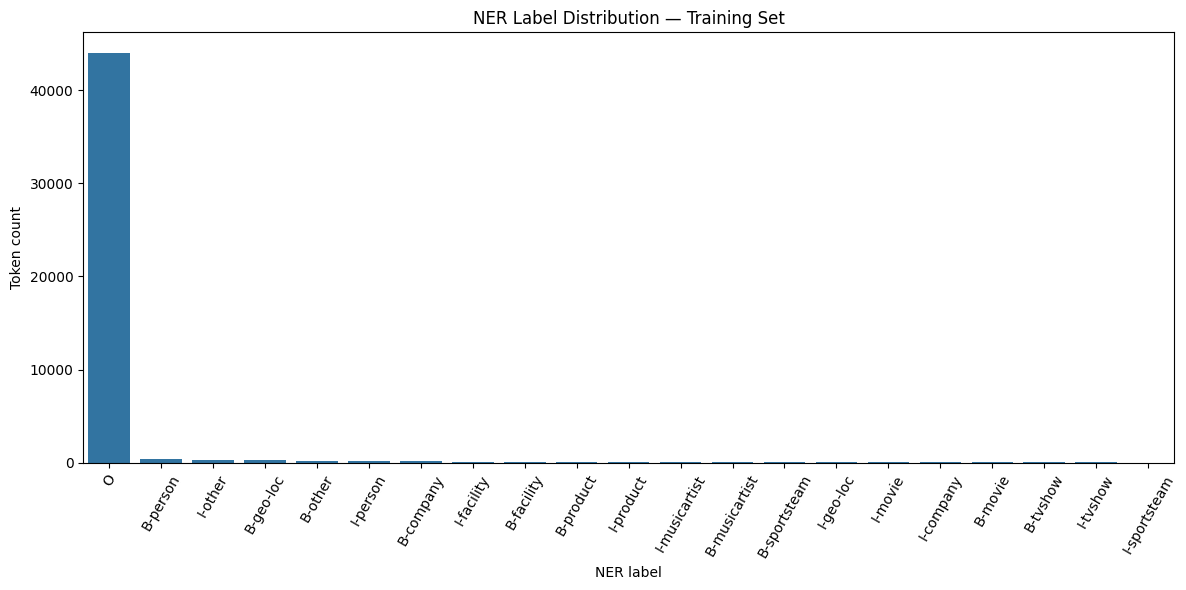

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=tag_distribution.index,
    y=tag_distribution["Training count"]
)

plt.title("NER Label Distribution — Training Set")
plt.xlabel("NER label")
plt.ylabel("Token count")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

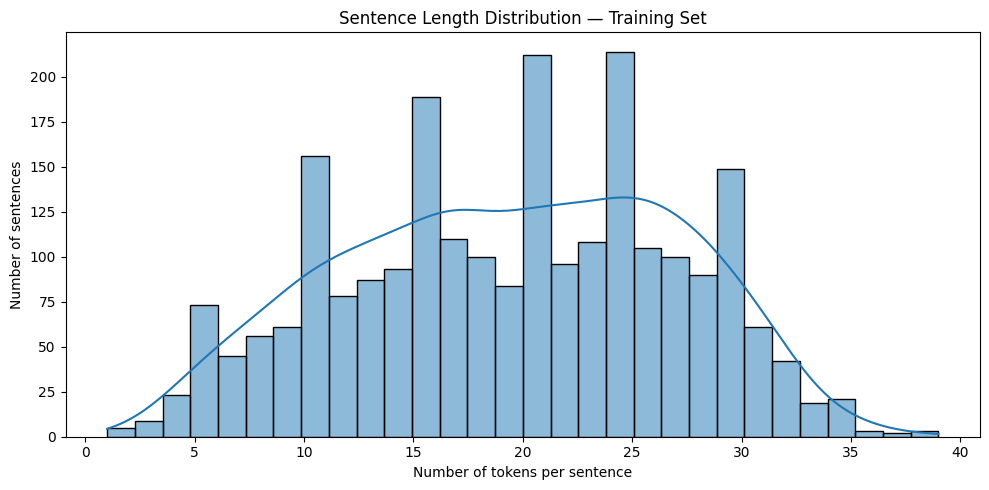

Median length: 20.0
95th percentile: 31.0
Maximum length: 39


In [ ]:
train_lengths = [
    len(sentence)
    for sentence in train_sentences
]

plt.figure(figsize=(10, 5))

sns.histplot(
    train_lengths,
    bins=30,
    kde=True
)

plt.title("Sentence Length Distribution — Training Set")
plt.xlabel("Number of tokens per sentence")
plt.ylabel("Number of sentences")
plt.tight_layout()
plt.show()

print("Median length:", np.median(train_lengths))
print("95th percentile:", np.percentile(train_lengths, 95))
print("Maximum length:", max(train_lengths))

In [ ]:
def count_entity_starts(sentences):
    entity_counts = Counter()

    for sentence in sentences:
        for token, tag in sentence:
            if tag.startswith("B-"):
                entity_type = tag[2:]
                entity_counts[entity_type] += 1

    return entity_counts


train_entity_counts = count_entity_starts(train_sentences)
test_entity_counts = count_entity_starts(test_sentences)

entity_distribution = pd.DataFrame({
    "Training entities": train_entity_counts,
    "Test entities": test_entity_counts,
}).fillna(0).astype(int)

entity_distribution = entity_distribution.sort_values(
    "Training entities",
    ascending=False
)

display(entity_distribution)

,Training entities,Test entities
person,449,482
geo-loc,276,882
other,225,584
company,171,621
facility,104,253
product,97,246
musicartist,55,191
sportsteam,51,147
movie,34,34
tvshow,34,33


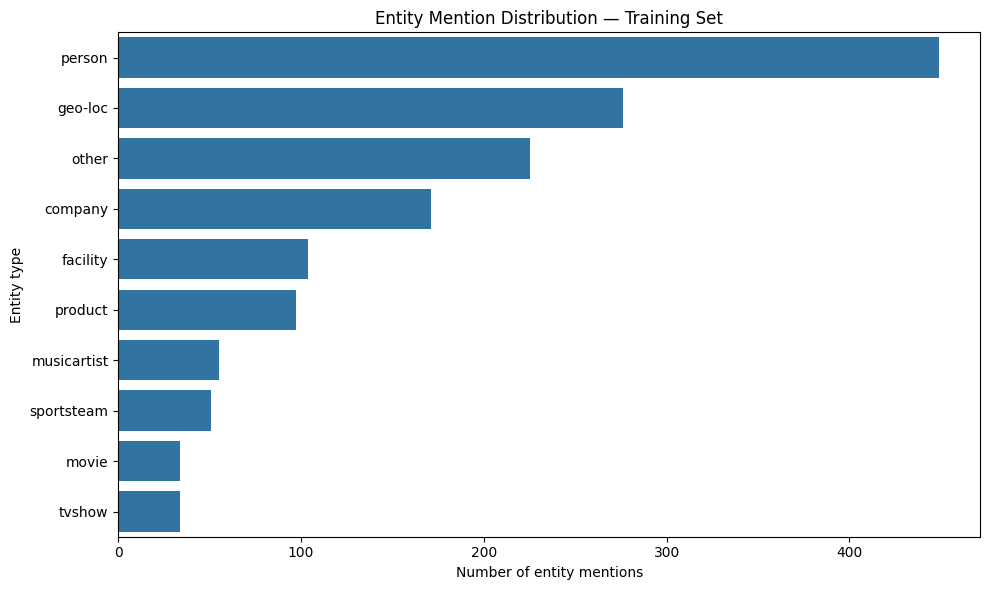

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=entity_distribution.reset_index(names="entity_type"),
    x="Training entities",
    y="entity_type"
)

plt.title("Entity Mention Distribution — Training Set")
plt.xlabel("Number of entity mentions")
plt.ylabel("Entity type")
plt.tight_layout()
plt.show()

In [ ]:
def find_bio_issues(sentences):
    issues = []

    for sentence_idx, sentence in enumerate(sentences):
        previous_tag = "O"

        for token, tag in sentence:
            if tag.startswith("I-"):
                entity_type = tag[2:]

                valid_previous = (
                    previous_tag == f"B-{entity_type}"
                    or previous_tag == f"I-{entity_type}"
                )

                if not valid_previous:
                    issues.append({
                        "sentence_index": sentence_idx,
                        "token": token,
                        "tag": tag,
                        "previous_tag": previous_tag,
                    })

            previous_tag = tag

    return pd.DataFrame(issues)


train_bio_issues = find_bio_issues(train_sentences)
test_bio_issues = find_bio_issues(test_sentences)

print("Training BIO issues:", len(train_bio_issues))
print("Test BIO issues:", len(test_bio_issues))

display(train_bio_issues.head(10))
display(test_bio_issues.head(10))

Training BIO issues: 0
Test BIO issues: 0


""


""


In [ ]:
# Collect all tokens from each dataset
train_vocab = {
    token
    for sentence in train_sentences
    for token, tag in sentence
}

test_vocab = {
    token
    for sentence in test_sentences
    for token, tag in sentence
}

# Tokens present in both datasets
common_vocab = train_vocab & test_vocab

# Tokens found in test but not in training
unseen_vocab = test_vocab - train_vocab

print("Unique training tokens:", len(train_vocab))
print("Unique test tokens:", len(test_vocab))
print("Common unique tokens:", len(common_vocab))
print("Unseen unique test tokens:", len(unseen_vocab))

print(
    "Unique test vocabulary unseen in training:",
    round(len(unseen_vocab) / len(test_vocab) * 100, 2),
    "%"
)

Unique training tokens: 10586
Unique test tokens: 18320
Common unique tokens: 3523
Unseen unique test tokens: 14797
Unique test vocabulary unseen in training: 80.77 %


In [ ]:
test_tokens = [
    token
    for sentence in test_sentences
    for token, tag in sentence
]

unseen_occurrences = sum(
    token not in train_vocab
    for token in test_tokens
)

print("Total test-token occurrences:", len(test_tokens))
print("Unseen test-token occurrences:", unseen_occurrences)

print(
    "Percentage of test occurrences unseen in training:",
    round(unseen_occurrences / len(test_tokens) * 100, 2),
    "%"
)

Total test-token occurrences: 61908
Unseen test-token occurrences: 21157
Percentage of test occurrences unseen in training: 34.17 %


In [ ]:
unseen_test_records = [
    (token, tag)
    for sentence in test_sentences
    for token, tag in sentence
    if token not in train_vocab
]

unseen_entity_records = [
    (token, tag)
    for token, tag in unseen_test_records
    if tag != "O"
]

unseen_non_entity_records = [
    (token, tag)
    for token, tag in unseen_test_records
    if tag == "O"
]

print("Unseen token occurrences:", len(unseen_test_records))
print("Unseen entity-token occurrences:", len(unseen_entity_records))
print("Unseen O-token occurrences:", len(unseen_non_entity_records))

print("\nUnseen entity tokens by label:")
print(Counter(tag for token, tag in unseen_entity_records))

Unseen token occurrences: 21157
Unseen entity-token occurrences: 3690
Unseen O-token occurrences: 17467

Unseen entity tokens by label:
Counter({'B-geo-loc': 508, 'B-company': 483, 'B-other': 410, 'B-person': 351, 'I-product': 239, 'I-person': 235, 'I-other': 225, 'I-facility': 211, 'B-product': 183, 'B-facility': 153, 'I-geo-loc': 151, 'B-musicartist': 127, 'I-company': 110, 'B-sportsteam': 107, 'I-musicartist': 79, 'I-sportsteam': 33, 'B-movie': 24, 'B-tvshow': 23, 'I-tvshow': 20, 'I-movie': 18})


##Preprocessing

In [ ]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    train_sentences,
    test_size=0.10,
    random_state=42,
    shuffle=True
)

print("Training sentences:", len(train_data))
print("Validation sentences:", len(val_data))
print("Test sentences:", len(test_sentences))

Training sentences: 2154
Validation sentences: 240
Test sentences: 3850


In [ ]:
len(train_data)

2154

In [ ]:
# Derive the label inventory from the training split only.
unique_labels = sorted({
    tag
    for sentence in train_data
    for token, tag in sentence
})

label2id = {
    label: idx
    for idx, label in enumerate(unique_labels)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

print("Number of labels:", len(label2id))
print("\nLabel to ID mapping:")

for label, idx in label2id.items():
    print(f"{label:15} -> {idx}")

Number of labels: 21

Label to ID mapping:
B-company       -> 0
B-facility      -> 1
B-geo-loc       -> 2
B-movie         -> 3
B-musicartist   -> 4
B-other         -> 5
B-person        -> 6
B-product       -> 7
B-sportsteam    -> 8
B-tvshow        -> 9
I-company       -> 10
I-facility      -> 11
I-geo-loc       -> 12
I-movie         -> 13
I-musicartist   -> 14
I-other         -> 15
I-person        -> 16
I-product       -> 17
I-sportsteam    -> 18
I-tvshow        -> 19
O               -> 20


In [ ]:
def collect_labels(sentences):
    return {
        tag
        for sentence in sentences
        for token, tag in sentence
    }


val_labels = collect_labels(val_data)
test_labels = collect_labels(test_sentences)

print("Validation labels missing from training:",
      sorted(val_labels - set(label2id)))

print("Test labels missing from training:",
      sorted(test_labels - set(label2id)))

Validation labels missing from training: []
Test labels missing from training: []


In [ ]:
def entity_type_counts(sentences):
    counts = Counter()

    for sentence in sentences:
        for token, tag in sentence:
            if tag.startswith("B-"):
                counts[tag[2:]] += 1

    return counts


coverage_df = pd.DataFrame({
    "Train": entity_type_counts(train_data),
    "Validation": entity_type_counts(val_data),
    "Test": entity_type_counts(test_sentences),
}).fillna(0).astype(int)

display(coverage_df)

,Train,Validation,Test
movie,32,2,34
geo-loc,246,30,882
other,202,23,584
company,149,22,621
product,84,13,246
tvshow,31,3,33
facility,97,7,253
person,406,43,482
musicartist,54,1,191
sportsteam,49,2,147


In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

In [ ]:
print("Tokenizer loaded:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)
print("Special tokens:", tokenizer.all_special_tokens)

Tokenizer loaded: bert-base-uncased
Vocabulary size: 30522
Special tokens: ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']


In [ ]:
example_sentence = train_data[0]

words = [
    token
    for token, tag in example_sentence
]

gold_tags = [
    tag
    for token, tag in example_sentence
]

encoded = tokenizer(
    words,
    is_split_into_words=True,
    add_special_tokens=True
)

print("Original words:")
print(words)

print("\nBERT tokens:")
print(tokenizer.convert_ids_to_tokens(
    encoded["input_ids"]
))

print("\nOriginal labels:")
print(gold_tags)

Original words:
['watching', 'camp', 'rock', '2', 'again', '...', 'all', 'the', 'way', 'through', 'this', 'time', ':P', '.']

BERT tokens:
['[CLS]', 'watching', 'camp', 'rock', '2', 'again', '.', '.', '.', 'all', 'the', 'way', 'through', 'this', 'time', ':', 'p', '.', '[SEP]']

Original labels:
['O', 'B-movie', 'I-movie', 'I-movie', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


In [ ]:
word_ids = encoded.word_ids()

alignment_df = pd.DataFrame({
    "BERT token": tokenizer.convert_ids_to_tokens(
        encoded["input_ids"]
    ),
    "Original word index": word_ids,
})

display(alignment_df)

,BERT token,Original word index
0,[CLS],NaN
1,watching,0.0
2,camp,1.0
3,rock,2.0
4,2,3.0
5,again,4.0
6,.,5.0
7,.,5.0
8,.,5.0
9,all,6.0


In [ ]:

IGNORE_INDEX = -100

word_ids = encoded.word_ids()
aligned_labels = []
previous_word_id = None

for word_id in word_ids:
    # Special tokens such as [CLS] and [SEP]
    if word_id is None:
        aligned_labels.append(IGNORE_INDEX)

    # First BERT token belonging to an original word
    elif word_id != previous_word_id:
        original_label = gold_tags[word_id]
        aligned_labels.append(label2id[original_label])

    # Additional subword pieces of the same original word
    else:
        aligned_labels.append(IGNORE_INDEX)

    previous_word_id = word_id

# Convert numerical labels back to readable names for inspection
readable_labels = [
    "IGNORED" if label == IGNORE_INDEX else id2label[label]
    for label in aligned_labels
]

alignment_check = pd.DataFrame({
    "BERT token": tokenizer.convert_ids_to_tokens(encoded["input_ids"]),
    "Original word index": word_ids,
    "Aligned label ID": aligned_labels,
    "Aligned label": readable_labels,
})

display(alignment_check)


,BERT token,Original word index,Aligned label ID,Aligned label
0,[CLS],NaN,-100,IGNORED
1,watching,0.0,20,O
2,camp,1.0,3,B-movie
3,rock,2.0,13,I-movie
4,2,3.0,13,I-movie
5,again,4.0,20,O
6,.,5.0,20,O
7,.,5.0,-100,IGNORED
8,.,5.0,-100,IGNORED
9,all,6.0,20,O


In [ ]:

!pip install -q datasets


In [ ]:

from datasets import Dataset

def prepare_dataset(sentences):
    # Separate original words and their numerical NER labels
    examples = {
        "tokens": [
            [token for token, tag in sentence]
            for sentence in sentences
        ],
        "ner_tags": [
            [label2id[tag] for token, tag in sentence]
            for sentence in sentences
        ]
    }

    dataset = Dataset.from_dict(examples)

    def tokenize_and_align_labels(batch):
        # Tokenize multiple sentences at once
        tokenized = tokenizer(
            batch["tokens"],
            is_split_into_words=True,
            truncation=True,
            max_length=128
        )

        aligned_batch_labels = []

        # Align each sentence's original labels with its BERT tokens
        for i, original_labels in enumerate(batch["ner_tags"]):
            word_ids = tokenized.word_ids(batch_index=i)

            aligned_labels = []
            previous_word_id = None

            for word_id in word_ids:
                if word_id is None:
                    aligned_labels.append(-100)

                elif word_id != previous_word_id:
                    aligned_labels.append(original_labels[word_id])

                else:
                    aligned_labels.append(-100)

                previous_word_id = word_id

            aligned_batch_labels.append(aligned_labels)

        tokenized["labels"] = aligned_batch_labels
        return tokenized

    # Remove the original columns after creating BERT-ready inputs
    tokenized_dataset = dataset.map(
        tokenize_and_align_labels,
        batched=True,
        remove_columns=dataset.column_names
    )

    return tokenized_dataset


In [ ]:

tokenized_train = prepare_dataset(train_data)
tokenized_val = prepare_dataset(val_data)
tokenized_test = prepare_dataset(test_sentences)

print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_val))
print("Test examples:", len(tokenized_test))

print("\nFeatures:", tokenized_train.column_names)
print("\nFirst processed example:")
print(tokenized_train[0])


Map:   0%|          | 0/2154 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/3850 [00:00<?, ? examples/s]

Training examples: 2154
Validation examples: 240
Test examples: 3850

Features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']

First processed example:
{'input_ids': [101, 3666, 3409, 2600, 1016, 2153, 1012, 1012, 1012, 2035, 1996, 2126, 2083, 2023, 2051, 1024, 1052, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels': [-100, 20, 3, 13, 13, 20, 20, -100, -100, 20, 20, 20, 20, 20, 20, 20, -100, 20, -100]}


In [ ]:
print(len(train_data[0]))
print(len(tokenized_train[0]["attention_mask"]))



14
19


In [ ]:

from transformers import AutoModelForTokenClassification

MODEL_NAME = "bert-base-uncased"

model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label2id),
    id2label=id2label,
    label2id=label2id
)

print("Model loaded successfully")
print("Number of NER labels:", model.config.num_labels)
print("Hidden size:", model.config.hidden_size)


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly

Model loaded successfully
Number of NER labels: 21
Hidden size: 768


In [ ]:

import torch

# Take one example from the tokenized training dataset
sample = tokenized_train[0]

# Convert input lists into tensors and add a batch dimension
input_ids = torch.tensor([sample["input_ids"]])
attention_mask = torch.tensor([sample["attention_mask"]])

model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

print("Input shape:", input_ids.shape)
print("Logits shape:", outputs.logits.shape)


Input shape: torch.Size([1, 19])
Logits shape: torch.Size([1, 19, 21])


In [ ]:

from transformers import DataCollatorForTokenClassification

data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer
)

# Take two examples with potentially different lengths
sample_examples = [
    tokenized_train[0],
    tokenized_train[1]
]

batch = data_collator(sample_examples)

for key, value in batch.items():
    print(f"{key}: {value.shape}")

print("\nInput IDs:")
print(batch["input_ids"])

print("\nAttention masks:")
print(batch["attention_mask"])

print("\nLabels:")
print(batch["labels"])


input_ids: torch.Size([2, 19])
token_type_ids: torch.Size([2, 19])
attention_mask: torch.Size([2, 19])
labels: torch.Size([2, 19])

Input IDs:
tensor([[  101,  3666,  3409,  2600,  1016,  2153,  1012,  1012,  1012,  2035,
          1996,  2126,  2083,  2023,  2051,  1024,  1052,  1012,   102],
        [  101,  6522,  2226, 29025,  2005,  1996,  2154,   999,  3407,  2632,
         11631,  2050,  5958,   999,   999,   999,   102,     0,     0]])

Attention masks:
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]])

Labels:
tensor([[-100,   20,    3,   13,   13,   20,   20, -100, -100,   20,   20,   20,
           20,   20,   20,   20, -100,   20, -100],
        [-100,   20, -100,   20,   20,   20,   20,   20,   20,   20, -100, -100,
           20,   20, -100, -100, -100, -100, -100]])


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
%pip install -q --upgrade pip setuptools wheel
%pip install -q seqeval accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 49.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cu130 requires setuptools<82, but you have setuptools 84.2.1 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.


In [ ]:
import seqeval
import accelerate

print("seqeval and accelerate installed successfully!")

seqeval and accelerate installed successfully!


In [ ]:

import numpy as np
from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction

    # Select the highest-scoring label for each token
    predictions = np.argmax(logits, axis=-1)

    true_predictions = []
    true_labels = []

    for prediction, label in zip(predictions, labels):
        sentence_predictions = []
        sentence_labels = []

        for pred_id, label_id in zip(prediction, label):
            # Ignore special tokens, extra subwords, and padding
            if label_id == -100:
                continue

            sentence_predictions.append(id2label[int(pred_id)])
            sentence_labels.append(id2label[int(label_id)])

        true_predictions.append(sentence_predictions)
        true_labels.append(sentence_labels)

    return {
        "precision": precision_score(true_labels, true_predictions),
        "recall": recall_score(true_labels, true_predictions),
        "f1": f1_score(true_labels, true_predictions),
    }


In [ ]:

import inspect
from transformers import TrainingArguments

# Support both newer and older Transformers versions
training_args_params = inspect.signature(TrainingArguments.__init__).parameters
eval_argument = (
    "eval_strategy"
    if "eval_strategy" in training_args_params
    else "evaluation_strategy"
)

training_kwargs = {
    "output_dir": "./bert_ner_results",
    "num_train_epochs": 5,
    "per_device_train_batch_size": 16,
    "per_device_eval_batch_size": 16,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
    "save_strategy": "epoch",
    "load_best_model_at_end": True,
    "metric_for_best_model": "f1",
    "greater_is_better": True,
    "logging_steps": 50,
    "report_to": "none",
    "fp16": torch.cuda.is_available(),
}

training_kwargs[eval_argument] = "epoch"

training_args = TrainingArguments(**training_kwargs)

print("Training configuration created successfully.")
print("Evaluation strategy: every epoch")
print("Best checkpoint metric: validation F1")


Training configuration created successfully.
Evaluation strategy: every epoch
Best checkpoint metric: validation F1


In [ ]:

from transformers import (
    Trainer,
    EarlyStoppingCallback
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=2)
    ],
)

print("Trainer configured successfully.")


Trainer configured successfully.


In [ ]:

# train_result = trainer.train()

# print("\nTraining completed.")
# print("Training metrics:")
# print(train_result.metrics)


In [ ]:

# validation_results = trainer.evaluate(tokenized_val)

# print("Validation results:")
# for metric, value in validation_results.items():
#     if isinstance(value, (int, float)):
#       print(f"{metric}: {value:.4f}")


In [ ]:

# test_results = trainer.evaluate(
#     eval_dataset=tokenized_test,
#     metric_key_prefix="test"
# )

# print("Final test results:")
# for metric, value in test_results.items():
#     if metric.startswith("test_") and isinstance(value, (int, float)):
#         print(f"{metric}: {value:.4f}")


##Inspection

In [ ]:

# from seqeval.metrics import classification_report

# test_output = trainer.predict(tokenized_test)
# test_logits = test_output.predictions
# test_labels = test_output.label_ids

# test_predictions = np.argmax(test_logits, axis=-1)

# true_predictions = []
# true_labels = []

# for predictions, labels in zip(test_predictions, test_labels):
#     pred_tags = []
#     gold_tags = []

#     for pred_id, label_id in zip(predictions, labels):
#         if label_id == -100:
#             continue

#         pred_tags.append(id2label[int(pred_id)])
#         gold_tags.append(id2label[int(label_id)])

#     true_predictions.append(pred_tags)
#     true_labels.append(gold_tags)

# print(classification_report(true_labels, true_predictions))


In [ ]:

# from seqeval.metrics import classification_report

# val_output = trainer.predict(tokenized_val)
# val_predictions = np.argmax(val_output.predictions, axis=-1)
# val_labels = val_output.label_ids

# val_true_predictions = []
# val_true_labels = []

# for predictions, labels in zip(val_predictions, val_labels):
#     pred_tags = []
#     gold_tags = []

#     for pred_id, label_id in zip(predictions, labels):
#         if label_id == -100:
#             continue

#         pred_tags.append(id2label[int(pred_id)])
#         gold_tags.append(id2label[int(label_id)])

#     val_true_predictions.append(pred_tags)
#     val_true_labels.append(gold_tags)

# print(classification_report(val_true_labels, val_true_predictions))


In [ ]:
# from transformers import AutoModelForTokenClassification

# reloaded_model = AutoModelForTokenClassification.from_pretrained(
#     "./bert_ner_model"
# )

# print("Model loaded successfully")
# print("Number of labels:", reloaded_model.config.num_labels)
# print("Model type:", reloaded_model.config.model_type)

In [ ]:

# import os

# print("Current directory:", os.getcwd())
# print("Model directory exists:", os.path.isdir("./bert_ner_model"))
# print("Files in current directory:", os.listdir(".")[:30])


In [ ]:
# import os

# for root, dirs, files in os.walk("/content/bert_ner_results"):
#     print(f"\nFolder: {root}")
#     print("Files:", files[:10])

In [ ]:

# from transformers import AutoModelForTokenClassification

# best_checkpoint_path = "/content/bert_ner_results/checkpoint-540"

# reloaded_model = AutoModelForTokenClassification.from_pretrained(
#     best_checkpoint_path,
#     local_files_only=True
# )

# print("Model loaded successfully")
# print("Number of labels:", reloaded_model.config.num_labels)
# print("Model type:", reloaded_model.config.model_type)



In [ ]:

# from transformers import AutoTokenizer

# save_path = "/content/bert_ner_model"

# reloaded_model.save_pretrained(save_path)
# tokenizer.save_pretrained(save_path)

# print("Model and tokenizer saved to:", save_path)


In [ ]:

# import json

# state_path = (
#     "/content/bert_ner_results/checkpoint-675/trainer_state.json"
# )

# with open(state_path, "r") as f:
#     state = json.load(f)

# print("Best checkpoint:", state.get("best_model_checkpoint"))
# print("Best metric:", state.get("best_metric"))


In [ ]:

# from transformers import AutoModelForTokenClassification, AutoTokenizer

# best_checkpoint_path = "/content/bert_ner_results/checkpoint-675"

# reloaded_model = AutoModelForTokenClassification.from_pretrained(
#     best_checkpoint_path,
#     local_files_only=True
# )

# reloaded_tokenizer = AutoTokenizer.from_pretrained(
#     best_checkpoint_path,
#     local_files_only=True
# )

# print("Best checkpoint loaded successfully")
# print("Number of labels:", reloaded_model.config.num_labels)
# print("Checkpoint:", best_checkpoint_path)


In [ ]:

# import inspect
# import gc
# import numpy as np
# import torch

# from transformers import (
#     AutoModelForTokenClassification,
#     TrainingArguments,
#     Trainer,
#     EarlyStoppingCallback,
# )

# MODEL_NAME = "bert-base-uncased"

# def run_bert_experiment(learning_rate, run_name):
#     model = AutoModelForTokenClassification.from_pretrained(
#         MODEL_NAME,
#         num_labels=len(label2id),
#         id2label=id2label,
#         label2id=label2id,
#     )

#     params = inspect.signature(TrainingArguments.__init__).parameters
#     eval_key = (
#         "eval_strategy" if "eval_strategy" in params
#         else "evaluation_strategy"
#     )

#     args_dict = {
#         "output_dir": f"./experiments/{run_name}",
#         "num_train_epochs": 5,
#         "per_device_train_batch_size": 16,
#         "per_device_eval_batch_size": 16,
#         "learning_rate": learning_rate,
#         "weight_decay": 0.01,
#         "save_strategy": "epoch",
#         "load_best_model_at_end": True,
#         "metric_for_best_model": "f1",
#         "greater_is_better": True,
#         "logging_steps": 50,
#         "report_to": "none",
#         "fp16": torch.cuda.is_available(),
#         "seed": 42,
#         "data_seed": 42,
#     }
#     args_dict[eval_key] = "epoch"

#     args = TrainingArguments(**args_dict)

#     trainer = Trainer(
#         model=model,
#         args=args,
#         train_dataset=tokenized_train,
#         eval_dataset=tokenized_val,
#         data_collator=data_collator,
#         compute_metrics=compute_metrics,
#         callbacks=[
#             EarlyStoppingCallback(early_stopping_patience=2)
#         ],
#     )

#     trainer.train()
#     results = trainer.evaluate(tokenized_val)

#     result = {
#         "run": run_name,
#         "learning_rate": learning_rate,
#         "best_validation_f1": trainer.state.best_metric,
#         "best_checkpoint": trainer.state.best_model_checkpoint,
#         "final_eval_f1": results.get("eval_f1"),
#         "final_eval_precision": results.get("eval_precision"),
#         "final_eval_recall": results.get("eval_recall"),
#     }

#     # Save the best model and tokenizer for this experiment
#     trainer.save_model(f"./experiments/{run_name}/best_model")
#     tokenizer.save_pretrained(f"./experiments/{run_name}/best_model")

#     del trainer, model
#     gc.collect()
#     if torch.cuda.is_available():
#         torch.cuda.empty_cache()

#     return result


In [ ]:

# result_lr1 = run_bert_experiment(
#     learning_rate=1e-5,
#     run_name="bert_lr_1e5"
# )

# print(result_lr1)


In [ ]:

# result_lr2 = run_bert_experiment(
#     learning_rate=2e-5,
#     run_name="bert_lr_2e5"
# )

# print(result_lr2)


In [ ]:

# result_lr3 = run_bert_experiment(
#     learning_rate=3e-5,
#     run_name="bert_lr_3e5"
# )

# print(result_lr3)


##Pretrained Tweet Bert Model


In [ ]:

# from transformers import AutoTokenizer

# TWITTER_MODEL = "vinai/bertweet-base"

# twitter_tokenizer = AutoTokenizer.from_pretrained(
#     TWITTER_MODEL,
#     use_fast=True
# )

# print("Tokenizer:", TWITTER_MODEL)
# print("Fast tokenizer:", twitter_tokenizer.is_fast)
# print("Vocabulary size:", twitter_tokenizer.vocab_size)
# print("Special tokens:", twitter_tokenizer.all_special_tokens)


In [ ]:

# def prepare_twitter_dataset(sentences):
#     examples = {
#         "tokens": [
#             [token for token, tag in sentence]
#             for sentence in sentences
#         ],
#         "ner_tags": [
#             [label2id[tag] for token, tag in sentence]
#             for sentence in sentences
#         ],
#     }

#     dataset = Dataset.from_dict(examples)

#     def tokenize_and_align_labels(batch):
#         tokenized = twitter_tokenizer(
#             batch["tokens"],
#             is_split_into_words=True,
#             truncation=True,
#             max_length=128,
#         )

#         all_labels = []

#         for i, original_labels in enumerate(batch["ner_tags"]):
#             word_ids = tokenized.word_ids(batch_index=i)
#             aligned = []
#             previous_word_id = None

#             for word_id in word_ids:
#                 if word_id is None:
#                     aligned.append(-100)
#                 elif word_id != previous_word_id:
#                     aligned.append(original_labels[word_id])
#                 else:
#                     aligned.append(-100)

#                 previous_word_id = word_id

#             all_labels.append(aligned)

#         tokenized["labels"] = all_labels
#         return tokenized

#     return dataset.map(
#         tokenize_and_align_labels,
#         batched=True,
#         remove_columns=dataset.column_names,
#     )


# twitter_train = prepare_twitter_dataset(train_data)
# twitter_val = prepare_twitter_dataset(val_data)

# print("Training examples:", len(twitter_train))
# print("Validation examples:", len(twitter_val))
# print("Features:", twitter_train.column_names)


In [ ]:
# print("Tokenizer class:", type(twitter_tokenizer).__name__)
# print("Is fast:", twitter_tokenizer.is_fast)

In [ ]:
# from transformers import AutoTokenizer

# TWITTER_MODEL = "vinai/bertweet-base"

# twitter_tokenizer = AutoTokenizer.from_pretrained(
#     TWITTER_MODEL,
#     use_fast=True
# )

# print("Tokenizer class:", type(twitter_tokenizer).__name__)
# print("Is fast:", twitter_tokenizer.is_fast)

In [ ]:
# from transformers import AutoTokenizer

# TWITTER_MODEL = "cardiffnlp/twitter-roberta-base"

# twitter_tokenizer = AutoTokenizer.from_pretrained(
#     TWITTER_MODEL,
#     use_fast=True
# )

# print("Tokenizer:", type(twitter_tokenizer).__name__)
# print("Is fast:", twitter_tokenizer.is_fast)

In [ ]:
# twitter_train = prepare_twitter_dataset(train_data)
# twitter_val = prepare_twitter_dataset(val_data)

# print("Training examples:", len(twitter_train))
# print("Validation examples:", len(twitter_val))

In [ ]:
# import torch
# from transformers import (
#     AutoModelForTokenClassification,
#     DataCollatorForTokenClassification
# )

# twitter_model = AutoModelForTokenClassification.from_pretrained(
#     TWITTER_MODEL,
#     num_labels=len(label2id),
#     id2label=id2label,
#     label2id=label2id
# )

# twitter_collator = DataCollatorForTokenClassification(
#     tokenizer=twitter_tokenizer
# )

In [ ]:
# from datasets import Dataset

# def prepare_twitter_dataset(sentences):
#     examples = {
#         "tokens": [
#             [token for token, tag in sentence]
#             for sentence in sentences
#         ],
#         "ner_tags": [
#             [label2id[tag] for token, tag in sentence]
#             for sentence in sentences
#         ]
#     }

#     dataset = Dataset.from_dict(examples)

#     def tokenize_and_align_labels(batch):
#         tokenized = twitter_tokenizer(
#             batch["tokens"],
#             is_split_into_words=True,
#             truncation=True,
#             max_length=128
#         )

#         aligned_batch_labels = []

#         for i, original_labels in enumerate(batch["ner_tags"]):
#             word_ids = tokenized.word_ids(batch_index=i)

#             aligned_labels = []
#             previous_word_id = None

#             for word_id in word_ids:
#                 if word_id is None:
#                     aligned_labels.append(-100)
#                 elif word_id != previous_word_id:
#                     aligned_labels.append(original_labels[word_id])
#                 else:
#                     aligned_labels.append(-100)

#                 previous_word_id = word_id

#             aligned_batch_labels.append(aligned_labels)

#         tokenized["labels"] = aligned_batch_labels
#         return tokenized

#     return dataset.map(
#         tokenize_and_align_labels,
#         batched=True,
#         remove_columns=dataset.column_names
#     )


# twitter_train = prepare_twitter_dataset(train_data)
# twitter_val = prepare_twitter_dataset(val_data)

# print("Training examples:", len(twitter_train))
# print("Validation examples:", len(twitter_val))
# print("Features:", twitter_train.column_names)

In [ ]:
# import torch
# from transformers import (
#     AutoModelForTokenClassification,
#     DataCollatorForTokenClassification
# )

# twitter_model = AutoModelForTokenClassification.from_pretrained(
#     TWITTER_MODEL,
#     num_labels=len(label2id),
#     id2label=id2label,
#     label2id=label2id
# )

# twitter_collator = DataCollatorForTokenClassification(
#     tokenizer=twitter_tokenizer
# )

# print("Number of labels:", len(label2id))
# print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

In [ ]:
# import inspect
# import gc
# from transformers import (
#     TrainingArguments,
#     Trainer,
#     EarlyStoppingCallback
# )

# params = inspect.signature(TrainingArguments.__init__).parameters
# eval_key = (
#     "eval_strategy"
#     if "eval_strategy" in params
#     else "evaluation_strategy"
# )

# args_dict = {
#     "output_dir": "./experiments/twitter_roberta",
#     "num_train_epochs": 5,
#     "per_device_train_batch_size": 16,
#     "per_device_eval_batch_size": 16,
#     "learning_rate": 3e-5,
#     "weight_decay": 0.01,
#     "save_strategy": "epoch",
#     "load_best_model_at_end": True,
#     "metric_for_best_model": "f1",
#     "greater_is_better": True,
#     "logging_steps": 50,
#     "report_to": "none",
#     "fp16": torch.cuda.is_available(),
#     "seed": 42,
#     "data_seed": 42
# }

# args_dict[eval_key] = "epoch"

# twitter_args = TrainingArguments(**args_dict)

# twitter_trainer = Trainer(
#     model=twitter_model,
#     args=twitter_args,
#     train_dataset=twitter_train,
#     eval_dataset=twitter_val,
#     data_collator=twitter_collator,
#     compute_metrics=compute_metrics,
#     callbacks=[
#         EarlyStoppingCallback(early_stopping_patience=2)
#     ]
# )

# twitter_train_output = twitter_trainer.train()

In [ ]:
# twitter_results = twitter_trainer.evaluate(twitter_val)

# print("\nValidation results:")
# print(f"Precision: {twitter_results['eval_precision']:.4f}")
# print(f"Recall:    {twitter_results['eval_recall']:.4f}")
# print(f"F1 score:  {twitter_results['eval_f1']:.4f}")

# print("\nBest validation F1:", twitter_trainer.state.best_metric)
# print("Best checkpoint:", twitter_trainer.state.best_model_checkpoint)

# SAVE_PATH = "./experiments/twitter_roberta/best_model"

# twitter_trainer.save_model(SAVE_PATH)
# twitter_tokenizer.save_pretrained(SAVE_PATH)

# print("Best model and tokenizer saved.")

In [ ]:
# print("Model comparison")
# print("-" * 42)
# print(f"BERT-base validation F1:       {0.579618:.4f}")
# print(f"Twitter-RoBERTa validation F1: {twitter_trainer.state.best_metric:.4f}")

##Class weights loss


In [ ]:
# import numpy as np
# import torch
# from sklearn.utils.class_weight import compute_class_weight

# # Count labels only from the training split.
# train_label_ids = [
#     label2id[tag]
#     for sentence in train_data
#     for _, tag in sentence
# ]

# classes = np.arange(len(label2id))

# weights = compute_class_weight(
#     class_weight="balanced",
#     classes=classes,
#     y=np.array(train_label_ids)
# )

# class_weights = torch.tensor(weights, dtype=torch.float32)

# # Avoid making the dominant O class artificially influential.
# class_weights[label2id["O"]] = 1.0

# print("Label weights:")
# for label, idx in label2id.items():
#     print(f"{label:15s}: {class_weights[idx].item():.3f}")

In [ ]:
# import torch.nn as nn
# from transformers import (
#     AutoModelForTokenClassification,
#     Trainer,
#     TrainingArguments,
#     EarlyStoppingCallback
# )

# class WeightedLossTrainer(Trainer):
#     def __init__(self, *args, class_weights=None, **kwargs):
#         super().__init__(*args, **kwargs)
#         self.class_weights = class_weights

#     def compute_loss(
#         self,
#         model,
#         inputs,
#         return_outputs=False,
#         num_items_in_batch=None
#     ):
#         labels = inputs.pop("labels")
#         outputs = model(**inputs)
#         logits = outputs.logits

#         weights = self.class_weights.to(logits.device)

#         loss_fn = nn.CrossEntropyLoss(
#             weight=weights,
#             ignore_index=-100
#         )

#         loss = loss_fn(
#             logits.reshape(-1, logits.shape[-1]),
#             labels.reshape(-1)
#         )

#         return (loss, outputs) if return_outputs else loss

In [ ]:
# MODEL_NAME = "bert-base-uncased"

# weighted_model = AutoModelForTokenClassification.from_pretrained(
#     MODEL_NAME,
#     num_labels=len(label2id),
#     id2label=id2label,
#     label2id=label2id
# )

# args_dict = {
#     "output_dir": "./experiments/bert_weighted",
#     "num_train_epochs": 5,
#     "per_device_train_batch_size": 16,
#     "per_device_eval_batch_size": 16,
#     "learning_rate": 3e-5,
#     "weight_decay": 0.01,
#     "save_strategy": "epoch",
#     "load_best_model_at_end": True,
#     "metric_for_best_model": "f1",
#     "greater_is_better": True,
#     "logging_steps": 50,
#     "report_to": "none",
#     "fp16": torch.cuda.is_available(),
#     "seed": 42,
#     "data_seed": 42
# }

# args_dict[eval_key] = "epoch"
# weighted_args = TrainingArguments(**args_dict)

# weighted_trainer = WeightedLossTrainer(
#     model=weighted_model,
#     args=weighted_args,
#     train_dataset=tokenized_train,
#     eval_dataset=tokenized_val,
#     data_collator=data_collator,
#     compute_metrics=compute_metrics,
#     class_weights=class_weights,
#     callbacks=[
#         EarlyStoppingCallback(early_stopping_patience=2)
#     ]
# )

# weighted_trainer.train()

In [ ]:
# weighted_results = weighted_trainer.evaluate(tokenized_val)

# print(f"BERT baseline F1:       {0.579618:.4f}")
# print(f"Weighted BERT F1:       {weighted_results['eval_f1']:.4f}")
# print(f"Weighted precision:     {weighted_results['eval_precision']:.4f}")
# print(f"Weighted recall:        {weighted_results['eval_recall']:.4f}")

In [ ]:
# from transformers import AutoModelForTokenClassification

# BASELINE_PATH = "./experiments/bert_lr_3e5/best_model"

# model_finetune = AutoModelForTokenClassification.from_pretrained(
#     BASELINE_PATH
# )

In [ ]:
# args_dict = {
#     "output_dir": "./experiments/bert_finetune_2e5",
#     "num_train_epochs": 2,
#     "per_device_train_batch_size": 16,
#     "per_device_eval_batch_size": 16,
#     "learning_rate": 2e-5,
#     "weight_decay": 0.01,
#     "save_strategy": "epoch",
#     "load_best_model_at_end": True,
#     "metric_for_best_model": "f1",
#     "greater_is_better": True,
#     "logging_steps": 50,
#     "report_to": "none",
#     "fp16": torch.cuda.is_available(),
#     "seed": 42,
#     "data_seed": 42
# }

# args_dict[eval_key] = "epoch"
# finetune_args = TrainingArguments(**args_dict)

# finetune_trainer = Trainer(
#     model=model_finetune,
#     args=finetune_args,
#     train_dataset=tokenized_train,
#     eval_dataset=tokenized_val,
#     data_collator=data_collator,
#     compute_metrics=compute_metrics,
#     callbacks=[
#         EarlyStoppingCallback(early_stopping_patience=2)
#     ]
# )

# finetune_trainer.train()

In [ ]:
# results = finetune_trainer.evaluate(tokenized_val)

# print(f"Baseline F1:       {0.579618:.4f}")
# print(f"Fine-tuned F1:     {results['eval_f1']:.4f}")
# print(f"Precision:         {results['eval_precision']:.4f}")
# print(f"Recall:            {results['eval_recall']:.4f}")

In [ ]:
# from transformers import AutoModelForTokenClassification, Trainer
# from seqeval.metrics import classification_report

# baseline_model = AutoModelForTokenClassification.from_pretrained(
#     "./experiments/bert_lr_3e5/best_model"
# )

# baseline_trainer = Trainer(
#     model=baseline_model,
#     data_collator=data_collator,
#     compute_metrics=compute_metrics
# )

# pred_output = baseline_trainer.predict(tokenized_val)

# logits = pred_output.predictions
# true_ids = pred_output.label_ids
# pred_ids = np.argmax(logits, axis=-1)

# true_labels = []
# pred_labels = []

# for pred_row, true_row in zip(pred_ids, true_ids):
#     row_true = []
#     row_pred = []

#     for pred_id, true_id in zip(pred_row, true_row):
#         if true_id == -100:
#             continue

#         row_true.append(id2label[int(true_id)])
#         row_pred.append(id2label[int(pred_id)])

#     true_labels.append(row_true)
#     pred_labels.append(row_pred)

# print(classification_report(true_labels, pred_labels, digits=3))

In [ ]:
# shown = 0

# for sentence, gold_tags, pred_tags in zip(
#     val_data, true_labels, pred_labels
# ):
#     tokens = [token for token, tag in sentence]

#     if len(tokens) != len(gold_tags):
#         continue

#     if gold_tags != pred_tags:
#         print("TOKENS:", tokens)
#         print("GOLD:  ", gold_tags)
#         print("PRED:  ", pred_tags)
#         print("-" * 80)

#         shown += 1
#         if shown == 10:
#             break

In [ ]:
# import re

# all_train_tokens = [
#     token
#     for sentence in train_data
#     for token, tag in sentence
# ]

# url_pattern = re.compile(r"https?://|www\.", re.IGNORECASE)
# mention_pattern = re.compile(r"^@[\w_]+")
# hashtag_pattern = re.compile(r"^#")

# print("Total training tokens:", len(all_train_tokens))
# print(
#     "URL-like tokens:",
#     sum(bool(url_pattern.search(t)) for t in all_train_tokens)
# )
# print(
#     "Mention tokens:",
#     sum(bool(mention_pattern.match(t)) for t in all_train_tokens)
# )
# print(
#     "Hashtag tokens:",
#     sum(bool(hashtag_pattern.match(t)) for t in all_train_tokens)
# )

In [ ]:
# import re

# URL_PATTERN = re.compile(r"^(https?://|www\.)", re.IGNORECASE)
# MENTION_PATTERN = re.compile(r"^@[\w_]+$")

# def normalize_twitter_token(token):
#     if URL_PATTERN.match(token):
#         return "[URL]"
#     if MENTION_PATTERN.match(token):
#         return "@USER"
#     return token

# def normalize_sentences(sentences):
#     return [
#         [
#             (normalize_twitter_token(token), tag)
#             for token, tag in sentence
#         ]
#         for sentence in sentences
#     ]

# train_data_norm = normalize_sentences(train_data)
# val_data_norm = normalize_sentences(val_data)

# print("Original:", train_data[0][:8])
# print("Normalized:", train_data_norm[0][:8])

In [ ]:
# tokenized_train_norm = prepare_dataset(train_data_norm)
# tokenized_val_norm = prepare_dataset(val_data_norm)

# print("Training examples:", len(tokenized_train_norm))
# print("Validation examples:", len(tokenized_val_norm))

In [ ]:
# from transformers import (
#     AutoModelForTokenClassification,
#     TrainingArguments,
#     Trainer,
#     EarlyStoppingCallback
# )
# import torch
# import inspect

# norm_model = AutoModelForTokenClassification.from_pretrained(
#     "bert-base-uncased",
#     num_labels=len(label2id),
#     id2label=id2label,
#     label2id=label2id
# )

# args_dict = {
#     "output_dir": "./experiments/bert_normalized",
#     "num_train_epochs": 5,
#     "per_device_train_batch_size": 16,
#     "per_device_eval_batch_size": 16,
#     "learning_rate": 3e-5,
#     "weight_decay": 0.01,
#     "save_strategy": "epoch",
#     "load_best_model_at_end": True,
#     "metric_for_best_model": "f1",
#     "greater_is_better": True,
#     "logging_steps": 50,
#     "report_to": "none",
#     "fp16": torch.cuda.is_available(),
#     "seed": 42,
#     "data_seed": 42
# }

# params = inspect.signature(TrainingArguments.__init__).parameters
# eval_key = "eval_strategy" if "eval_strategy" in params else "evaluation_strategy"
# args_dict[eval_key] = "epoch"

# norm_args = TrainingArguments(**args_dict)

# norm_trainer = Trainer(
#     model=norm_model,
#     args=norm_args,
#     train_dataset=tokenized_train_norm,
#     eval_dataset=tokenized_val_norm,
#     data_collator=data_collator,
#     compute_metrics=compute_metrics,
#     callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
# )

# norm_trainer.train()

In [ ]:
# norm_results = norm_trainer.evaluate(tokenized_val_norm)

# print(f"Original BERT F1:      {0.579618:.4f}")
# print(f"Normalized BERT F1:    {norm_results['eval_f1']:.4f}")
# print(f"Precision:             {norm_results['eval_precision']:.4f}")
# print(f"Recall:                {norm_results['eval_recall']:.4f}")

In [ ]:
# import torch
# import inspect

# from transformers import (
#     AutoModelForTokenClassification,
#     TrainingArguments,
#     Trainer,
#     EarlyStoppingCallback
# )

# # Start from the original pretrained BERT, not a failed experiment.
# model_warmup = AutoModelForTokenClassification.from_pretrained(
#     "bert-base-uncased",
#     num_labels=len(label2id),
#     id2label=id2label,
#     label2id=label2id
# )

# params = inspect.signature(TrainingArguments.__init__).parameters

# eval_key = (
#     "eval_strategy"
#     if "eval_strategy" in params
#     else "evaluation_strategy"
# )

# args_dict = {
#     "output_dir": "./experiments/bert_warmup",
#     "num_train_epochs": 5,
#     "per_device_train_batch_size": 16,
#     "per_device_eval_batch_size": 16,
#     "learning_rate": 3e-5,
#     "weight_decay": 0.01,

#     # New experiment setting
#     "warmup_steps": 50,
#     "lr_scheduler_type": "linear",

#     "save_strategy": "epoch",
#     "load_best_model_at_end": True,
#     "metric_for_best_model": "f1",
#     "greater_is_better": True,
#     "logging_steps": 50,
#     "report_to": "none",
#     "fp16": torch.cuda.is_available(),
#     "seed": 42,
#     "data_seed": 42
# }

# args_dict[eval_key] = "epoch"

# warmup_args = TrainingArguments(**args_dict)

# warmup_trainer = Trainer(
#     model=model_warmup,
#     args=warmup_args,
#     train_dataset=tokenized_train,
#     eval_dataset=tokenized_val,
#     data_collator=data_collator,
#     compute_metrics=compute_metrics,
#     callbacks=[
#         EarlyStoppingCallback(early_stopping_patience=2)
#     ]
# )

# warmup_trainer.train()

In [ ]:
# warmup_results = warmup_trainer.evaluate(tokenized_val)

# print(f"Baseline BERT F1:  {0.579618:.4f}")
# print(f"Warmup BERT F1:    {warmup_results['eval_f1']:.4f}")
# print(f"Precision:         {warmup_results['eval_precision']:.4f}")
# print(f"Recall:            {warmup_results['eval_recall']:.4f}")

# print("Best checkpoint:", warmup_trainer.state.best_model_checkpoint)

##BERT + CRF

In [ ]:
%pip install pytorch-crf

In [ ]:
import torch
import torch.nn as nn

from transformers import (
    AutoModel,
    AutoConfig,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)
from transformers.modeling_outputs import TokenClassifierOutput
from torchcrf import CRF

In [ ]:
# class BertCrfForNER(nn.Module):
#     def __init__(self, model_name, num_labels):
#         super().__init__()

#         self.config = AutoConfig.from_pretrained(model_name)
#         self.bert = AutoModel.from_pretrained(model_name, config=self.config)

#         self.dropout = nn.Dropout(0.1)
#         self.classifier = nn.Linear(
#             self.config.hidden_size,
#             num_labels
#         )

#         self.crf = CRF(num_labels, batch_first=True)
#         self.num_labels = num_labels

#     def forward(
#         self,
#         input_ids,
#         attention_mask=None,
#         token_type_ids=None,
#         labels=None
#     ):
#         bert_inputs = {
#             "input_ids": input_ids,
#             "attention_mask": attention_mask
#         }

#         if token_type_ids is not None:
#             bert_inputs["token_type_ids"] = token_type_ids

#         outputs = self.bert(**bert_inputs)
#         emissions = self.classifier(
#             self.dropout(outputs.last_hidden_state)
#         )

#         loss = None
#         decoded_logits = emissions

#         if labels is not None:
#             # Keep only positions corresponding to original words.
#             valid_mask = labels.ne(-100)
#             lengths = valid_mask.sum(dim=1)
#             max_words = int(lengths.max().item())

#             batch_size = labels.size(0)
#             device = labels.device

#             compact_emissions = emissions.new_zeros(
#                 batch_size, max_words, self.num_labels
#             )
#             compact_labels = torch.zeros(
#                 batch_size, max_words,
#                 dtype=torch.long,
#                 device=device
#             )
#             crf_mask = torch.zeros(
#                 batch_size, max_words,
#                 dtype=torch.bool,
#                 device=device
#             )

#             for i in range(batch_size):
#                 positions = torch.where(valid_mask[i])[0]
#                 length = len(positions)

#                 compact_emissions[i, :length] = emissions[
#                     i, positions
#                 ]
#                 compact_labels[i, :length] = labels[
#                     i, positions
#                 ]
#                 crf_mask[i, :length] = True

#             # CRF maximizes sequence log-likelihood, so negate it.
#             loss = -self.crf(
#                 compact_emissions,
#                 compact_labels,
#                 mask=crf_mask,
#                 reduction="mean"
#             )

#             # During evaluation, decode the best label sequence.
#             if not self.training:
#                 best_paths = self.crf.decode(
#                     compact_emissions,
#                     mask=crf_mask
#                 )

#                 decoded_logits = emissions.new_full(
#                     emissions.shape, -1e4
#                 )

#                 for i, path in enumerate(best_paths):
#                     positions = torch.where(valid_mask[i])[0]

#                     for position, tag_id in zip(positions, path):
#                         decoded_logits[i, position, tag_id] = 0.0

#         return TokenClassifierOutput(
#             loss=loss,
#             logits=decoded_logits
#         )

In [ ]:

class BertCrfForNER(nn.Module):
    def __init__(self, model_name, num_labels):
        super().__init__()

        self.config = AutoConfig.from_pretrained(model_name)
        self.bert = AutoModel.from_pretrained(
            model_name, config=self.config
        )
        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(
            self.config.hidden_size, num_labels
        )
        self.crf = CRF(num_labels, batch_first=True)
        self.num_labels = num_labels

    def forward(
        self,
        input_ids,
        attention_mask=None,
        token_type_ids=None,
        labels=None,
        word_start_mask=None
    ):
        bert_inputs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask
        }

        if token_type_ids is not None:
            bert_inputs["token_type_ids"] = token_type_ids

        outputs = self.bert(**bert_inputs)

        emissions = self.classifier(
            self.dropout(outputs.last_hidden_state)
        )

        loss = None
        decoded_logits = emissions

        # During training/evaluation, labels identify word positions.
        # During standalone inference, word_start_mask does this.
        if labels is not None:
            valid_mask = labels.ne(-100)
        elif word_start_mask is not None:
            valid_mask = word_start_mask.bool()
        else:
            # Do not silently return raw emissions as CRF predictions.
            return TokenClassifierOutput(
                loss=None, logits=emissions
            )

        lengths = valid_mask.sum(dim=1)
        max_words = int(lengths.max().item())
        batch_size = input_ids.size(0)
        device = input_ids.device

        compact_emissions = emissions.new_zeros(
            batch_size, max_words, self.num_labels
        )
        crf_mask = torch.zeros(
            batch_size, max_words,
            dtype=torch.bool, device=device
        )

        compact_labels = None
        if labels is not None:
            compact_labels = torch.zeros(
                batch_size, max_words,
                dtype=torch.long, device=device
            )

        # Remove special tokens and non-first subwords.
        # CRF operates only on original word positions.
        for i in range(batch_size):
            positions = torch.where(valid_mask[i])[0]
            length = len(positions)

            compact_emissions[i, :length] = emissions[
                i, positions
            ]
            crf_mask[i, :length] = True

            if labels is not None:
                compact_labels[i, :length] = labels[
                    i, positions
                ]

        # Compute CRF loss when gold labels are available.
        if labels is not None:
            loss = -self.crf(
                compact_emissions,
                compact_labels,
                mask=crf_mask,
                reduction="mean"
            )

        # Decode when evaluating or doing standalone inference.
        should_decode = (
            not self.training or labels is None
        )

        if should_decode:
            best_paths = self.crf.decode(
                compact_emissions, mask=crf_mask
            )

            decoded_logits = emissions.new_full(
                emissions.shape, -1e4
            )

            for i, path in enumerate(best_paths):
                positions = torch.where(valid_mask[i])[0]

                for position, tag_id in zip(positions, path):
                    decoded_logits[i, position, tag_id] = 0.0

        return TokenClassifierOutput(
            loss=loss, logits=decoded_logits
        )


In [ ]:
crf_model = BertCrfForNER(
    model_name="bert-base-uncased",
    num_labels=len(label2id)
)

params = inspect.signature(
    TrainingArguments.__init__
).parameters

eval_key = (
    "eval_strategy"
    if "eval_strategy" in params
    else "evaluation_strategy"
)

crf_args_dict = {
    "output_dir": "./experiments/bert_crf",
    "num_train_epochs": 5,
    "per_device_train_batch_size": 8,
    "per_device_eval_batch_size": 8,
    "learning_rate": 3e-5,
    "weight_decay": 0.01,
    "save_strategy": "epoch",
    "load_best_model_at_end": True,
    "metric_for_best_model": "f1",
    "greater_is_better": True,
    "logging_steps": 50,
    "report_to": "none",
    "fp16": torch.cuda.is_available(),
    "seed": 42,
    "data_seed": 42
}

crf_args_dict[eval_key] = "epoch"

crf_args = TrainingArguments(**crf_args_dict)

crf_trainer = Trainer(
    model=crf_model,
    args=crf_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=2)
    ]
)

crf_trainer.train()

##Model Evaluation

In [ ]:
crf_results = crf_trainer.evaluate(tokenized_val)

print(f"Baseline BERT F1: {0.579618:.4f}")
print(f"BERT + CRF F1:    {crf_results['eval_f1']:.4f}")
print(f"Precision:        {crf_results['eval_precision']:.4f}")
print(f"Recall:           {crf_results['eval_recall']:.4f}")
print("Best checkpoint:", crf_trainer.state.best_model_checkpoint)

Saving model to drive

In [ ]:

# import os
# import torch

# # Permanent destination in Google Drive
# CRF_SAVE_PATH = "/content/drive/MyDrive/NER_Project/bert_crf_best"

# os.makedirs(CRF_SAVE_PATH, exist_ok=True)

# # Save model weights and configuration
# crf_trainer.save_model(CRF_SAVE_PATH)

# # Save the custom model's weights explicitly as an additional safeguard
# torch.save(
#     crf_trainer.model.state_dict(),
#     os.path.join(CRF_SAVE_PATH, "bert_crf_state_dict.pt")
# )

# print("Model saved to:", CRF_SAVE_PATH)
# print("Saved files:", os.listdir(CRF_SAVE_PATH))


In [ ]:
# CRF_SAVE_PATH = "./bert_crf_best"

# crf_trainer.save_model(CRF_SAVE_PATH)

In [ ]:

# import json

# # Save the label mappings
# with open(os.path.join(CRF_SAVE_PATH, "label2id.json"), "w") as f:
#     json.dump(label2id, f, indent=2)

# with open(os.path.join(CRF_SAVE_PATH, "id2label.json"), "w") as f:
#     json.dump({str(k): v for k, v in id2label.items()}, f, indent=2)

# # Save the tokenizer used by the original BERT model
# tokenizer.save_pretrained(CRF_SAVE_PATH)

# print("Label mappings and tokenizer saved.")


In [ ]:
# weights_path = os.path.join(
#     CRF_SAVE_PATH,
#     "bert_crf_state_dict.pt"
# )

# saved_state = torch.load(
#     weights_path,
#     map_location="cpu",
#     weights_only=True
# )

# print("Weight file exists:", os.path.exists(weights_path))
# print("Number of saved parameter tensors:", len(saved_state))
# print("Model folder size:", round(
#     sum(
#         os.path.getsize(os.path.join(CRF_SAVE_PATH, f))
#         for f in os.listdir(CRF_SAVE_PATH)
#         if os.path.isfile(os.path.join(CRF_SAVE_PATH, f))
#     ) / (1024**2), 2
# ), "MB")

In [ ]:
from seqeval.metrics import classification_report

val_output = crf_trainer.predict(tokenized_val)
val_logits = val_output.predictions
val_gold_ids = val_output.label_ids

import numpy as np

val_pred_ids = np.argmax(val_logits, axis=-1)

gold_sequences = []
pred_sequences = []

for pred_row, gold_row in zip(val_pred_ids, val_gold_ids):
    gold_tags = []
    pred_tags = []

    for pred_id, gold_id in zip(pred_row, gold_row):
        if gold_id == -100:
            continue

        gold_tags.append(id2label[int(gold_id)])
        pred_tags.append(id2label[int(pred_id)])

    gold_sequences.append(gold_tags)
    pred_sequences.append(pred_tags)

print(classification_report(
    gold_sequences,
    pred_sequences,
    digits=3
))

In [ ]:
test_output = crf_trainer.predict(tokenized_test)

print("Test metrics:")
for name, value in test_output.metrics.items():
    if name.startswith("test_"):
        print(f"{name}: {value:.4f}")

##Load model from drive

In [ ]:
import os
import json
import torch
from transformers import AutoTokenizer

MODEL_PATH = "/content/drive/MyDrive/NER_Project/bert_crf_best"

print(os.listdir(MODEL_PATH))

with open(os.path.join(MODEL_PATH, "label2id.json")) as f:
    label2id = json.load(f)

with open(os.path.join(MODEL_PATH, "id2label.json")) as f:
    id2label = {int(k): v for k, v in json.load(f).items()}

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

print("Labels:", len(label2id))
print("Tokenizer loaded successfully.")

['model.safetensors', 'training_args.bin', 'bert_crf_state_dict.pt', 'label2id.json', 'id2label.json', 'tokenizer_config.json', 'tokenizer.json']
Labels: 21
Tokenizer loaded successfully.


In [ ]:
from torchcrf import CRF

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BertCrfForNER(
    model_name="bert-base-uncased",
    num_labels=len(label2id)
)

weights_path = os.path.join(
    MODEL_PATH,
    "bert_crf_state_dict.pt"
)

state_dict = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict, strict=True)
model.to(device)
model.eval()

print("BERT + CRF model loaded successfully.")
print("Device:", device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT + CRF model loaded successfully.
Device: cuda


In [ ]:
from transformers import Trainer

crf_trainer = Trainer(
    model=model,  # Your loaded BERT + CRF model
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [ ]:
test_output = crf_trainer.predict(tokenized_test)

print("Test metrics:")
for name, value in test_output.metrics.items():
    if name.startswith("test_"):
        print(f"{name}: {value:.4f}")

Test metrics:
test_loss: 6.0076
test_model_preparation_time: 0.0147
test_precision: 0.4632
test_recall: 0.4834
test_f1: 0.4731
test_runtime: 52.2633
test_samples_per_second: 73.6650
test_steps_per_second: 9.2230


In [ ]:
tokens = ["Apple", "released", "a", "new", "product"]

inputs = tokenizer(
    tokens,
    is_split_into_words=True,
    return_tensors="pt",
    truncation=True
)

inputs = {k: v.to(device) for k, v in inputs.items()}

model.eval()

with torch.no_grad():
    outputs = model(**inputs)

print("Output shape:", outputs.logits.shape)

Output shape: torch.Size([1, 7, 21])


In [ ]:
word_ids = tokenizer(
    tokens,
    is_split_into_words=True,
    truncation=True
).word_ids()

predicted_ids = outputs.logits.argmax(dim=-1)[0].cpu().tolist()

word_predictions = {}
for word_id, pred_id in zip(word_ids, predicted_ids):
    if word_id is not None and word_id not in word_predictions:
        word_predictions[word_id] = id2label[pred_id]

for i, token in enumerate(tokens):
    print(f"{token:12s} -> {word_predictions.get(i, 'N/A')}")

Apple        -> B-company
released     -> O
a            -> O
new          -> O
product      -> O


##Insepct and further enhancements

In [ ]:
import torch
from seqeval.metrics import classification_report

model = crf_trainer.model
model.eval()

gold_sequences = []
pred_sequences = []

device = next(model.parameters()).device

for batch in crf_trainer.get_test_dataloader(tokenized_test):
    batch = {
        key: value.to(device)
        for key, value in batch.items()
    }

    labels = batch.pop("labels")

    with torch.no_grad():
        outputs = model(**batch)

    # The custom model returns decoded paths as one-hot-like scores
    # at the original word positions.
    predictions = outputs.logits.argmax(dim=-1)

    for pred_row, gold_row in zip(predictions, labels):
        valid = gold_row != -100
        pred_ids = pred_row[valid].tolist()
        gold_ids = gold_row[valid].tolist()

        pred_sequences.append([id2label[int(i)] for i in pred_ids])
        gold_sequences.append([id2label[int(i)] for i in gold_ids])

print(classification_report(gold_sequences, pred_sequences, digits=3))

              precision    recall  f1-score   support

     company      0.628     0.528     0.574       621
    facility      0.250     0.304     0.275       253
     geo-loc      0.616     0.741     0.673       882
       movie      0.212     0.206     0.209        34
 musicartist      0.317     0.105     0.157       191
       other      0.207     0.248     0.226       584
      person      0.516     0.753     0.613       482
     product      0.170     0.093     0.121       246
  sportsteam      0.569     0.422     0.484       147
      tvshow      0.000     0.000     0.000        33

   micro avg      0.461     0.483     0.472      3473
   macro avg      0.349     0.340     0.333      3473
weighted avg      0.449     0.483     0.456      3473



In [ ]:
# Check whether decoded predictions are one-hot-like
test_batch = next(iter(crf_trainer.get_test_dataloader(tokenized_test)))

device = next(model.parameters()).device
test_batch = {k: v.to(device) for k, v in test_batch.items()}

labels = test_batch.pop("labels")

model.eval()
with torch.no_grad():
    outputs = model(**test_batch)

pred_ids = outputs.logits.argmax(dim=-1)

print("Logits shape:", outputs.logits.shape)
print("Labels shape:", labels.shape)
print("Prediction IDs (first row):", pred_ids[0][:20].tolist())
print("Gold IDs (first row):", labels[0][:20].tolist())
print("Ignored positions:", (labels[0] == -100).sum().item())

Logits shape: torch.Size([8, 42, 21])
Labels shape: torch.Size([8, 42])
Prediction IDs (first row): [20, 2, 12, 15, 15, 15, 15, 15, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20]
Gold IDs (first row): [-100, 5, 15, 15, 15, -100, 15, 15, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, -100, -100]
Ignored positions: 16


In [ ]:
row = 0

valid_positions = torch.where(labels[row] != -100)[0]
predicted_at_valid = pred_ids[row, valid_positions]
gold_at_valid = labels[row, valid_positions]

print("First 15 valid token positions:", valid_positions[:15].tolist())
print("Predicted IDs:", predicted_at_valid[:15].tolist())
print("Gold IDs:     ", gold_at_valid[:15].tolist())

print("\nPredicted labels:")
print([id2label[int(i)] for i in predicted_at_valid[:15].cpu()])

print("\nGold labels:")
print([id2label[int(i)] for i in gold_at_valid[:15].cpu()])

First 15 valid token positions: [1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
Predicted IDs: [2, 12, 15, 15, 15, 15, 20, 20, 20, 20, 20, 20, 20, 20, 20]
Gold IDs:      [5, 15, 15, 15, 15, 15, 20, 20, 20, 20, 20, 20, 20, 20, 20]

Predicted labels:
['B-geo-loc', 'I-geo-loc', 'I-other', 'I-other', 'I-other', 'I-other', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']

Gold labels:
['B-other', 'I-other', 'I-other', 'I-other', 'I-other', 'I-other', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


In [ ]:

import os
import json
import torch
from transformers import AutoTokenizer, AutoConfig, AutoModel
from transformers.modeling_outputs import TokenClassifierOutput
from torchcrf import CRF

MODEL_PATH = "/content/drive/MyDrive/NER_Project/bert_crf_best"

with open(os.path.join(MODEL_PATH, "label2id.json")) as f:
    label2id = json.load(f)

with open(os.path.join(MODEL_PATH, "id2label.json")) as f:
    id2label = {int(k): v for k, v in json.load(f).items()}

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = BertCrfForNER(
    model_name="bert-base-uncased",
    num_labels=len(label2id)
)

state_dict = torch.load(
    os.path.join(MODEL_PATH, "bert_crf_state_dict.pt"),
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict, strict=True)
model.to(device)
model.eval()

print("Saved BERT + CRF model loaded successfully.")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Saved BERT + CRF model loaded successfully.


##Inference Demo

In [ ]:

words = [
    "Apple", "released", "a", "new",
    "iPhone", "in", "California", "."
]

# Tokenize the original words.
encoding = tokenizer(
    words,
    is_split_into_words=True,
    return_tensors="pt",
    truncation=True
)

# Identify the first subword of each original word.
word_ids = encoding.word_ids(batch_index=0)

word_start_mask = []
previous_word_id = None

for word_id in word_ids:
    is_word_start = (
        word_id is not None and word_id != previous_word_id
    )
    word_start_mask.append(is_word_start)
    previous_word_id = word_id

# Move model inputs and mask to the same device.
inputs = {
    key: value.to(device)
    for key, value in encoding.items()
}

inputs["word_start_mask"] = torch.tensor(
    [word_start_mask],
    dtype=torch.bool,
    device=device
)

# Predict using BERT + CRF.
with torch.no_grad():
    outputs = model(**inputs)

predicted_ids = outputs.logits.argmax(dim=-1)[0].cpu().tolist()

# Map predictions back to the original words.
for word_id, word in enumerate(words):
    token_position = next(
        i for i, wid in enumerate(word_ids)
        if wid == word_id
    )

    label = id2label[predicted_ids[token_position]]
    print(f"{word:15} -> {label}")


Apple           -> B-company
released        -> O
a               -> O
new             -> O
iPhone          -> B-product
in              -> O
California      -> B-geo-loc
.               -> O


In [ ]:

def predict_ner(sentence):
    model.eval()

    # Split the sentence into words.
    words = sentence.split()

    if not words:
        return []

    # Tokenize while preserving the original word boundaries.
    encoding = tokenizer(
        words,
        is_split_into_words=True,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    # Identify the first subword of each original word.
    word_ids = encoding.word_ids(batch_index=0)

    word_start_mask = []
    previous_word_id = None

    for word_id in word_ids:
        is_word_start = (
            word_id is not None
            and word_id != previous_word_id
        )
        word_start_mask.append(is_word_start)
        previous_word_id = word_id

    # Move inputs to the model's device.
    inputs = {
        key: value.to(device)
        for key, value in encoding.items()
    }

    inputs["word_start_mask"] = torch.tensor(
        [word_start_mask],
        dtype=torch.bool,
        device=device
    )

    # Run BERT + CRF inference.
    with torch.no_grad():
        outputs = model(**inputs)

    predicted_ids = (
        outputs.logits.argmax(dim=-1)[0].cpu().tolist()
    )

    # Map each original word to its predicted label.
    predictions = []
    seen_word_ids = set()

    for word_id, pred_id in zip(word_ids, predicted_ids):
        if word_id is None or word_id in seen_word_ids:
            continue

        seen_word_ids.add(word_id)

        predictions.append({
            "word": words[word_id],
            "label": id2label[pred_id]
        })

    return predictions


In [ ]:

def extract_entities(predictions):
    entities = []
    current_entity = None

    for item in predictions:
        word = item["word"]
        label = item["label"]

        if label == "O":
            if current_entity:
                entities.append(current_entity)
                current_entity = None
            continue

        prefix, entity_type = label.split("-", 1)

        if prefix == "B" or (
            current_entity
            and current_entity["type"] != entity_type
        ):
            if current_entity:
                entities.append(current_entity)

            current_entity = {
                "text": word,
                "type": entity_type
            }

        elif prefix == "I" and current_entity:
            current_entity["text"] += " " + word

        else:
            # Handle an I-tag without a preceding matching entity.
            current_entity = {
                "text": word,
                "type": entity_type
            }

    if current_entity:
        entities.append(current_entity)

    return entities


In [ ]:

sentences = [
    "Microsoft announced a new product in London.",
    "Apple released the iPhone in California.",
    "Barack Obama visited New York yesterday."
]

for sentence in sentences:
    print(f"\nSentence: {sentence}")
    for item in predict_ner(sentence):
        print(f"  {item['word']:15} -> {item['label']}")



Sentence: Microsoft announced a new product in London.
  Microsoft       -> B-company
  announced       -> O
  a               -> O
  new             -> O
  product         -> O
  in              -> O
  London.         -> B-geo-loc

Sentence: Apple released the iPhone in California.
  Apple           -> B-company
  released        -> O
  the             -> O
  iPhone          -> B-product
  in              -> O
  California.     -> B-geo-loc

Sentence: Barack Obama visited New York yesterday.
  Barack          -> B-person
  Obama           -> I-person
  visited         -> O
  New             -> B-geo-loc
  York            -> I-geo-loc
  yesterday.      -> O


In [ ]:

sentence = "Friends is the popular TV show fronm 90s in which my fav character was Chandler or Joey or Ross or Monica or Rachel, Phoebe."

predictions = predict_ner(sentence)
entities = extract_entities(predictions)
print("Predicted entities:")
for entity in entities:
    print(entity)


Predicted entities:
{'text': 'Chandler', 'type': 'person'}
{'text': 'Joey', 'type': 'person'}
{'text': 'Ross', 'type': 'person'}
{'text': 'Monica', 'type': 'person'}
{'text': 'Rachel,', 'type': 'person'}
{'text': 'Phoebe.', 'type': 'person'}



Sentence: Microsoft announced a new product in London.
  Microsoft       -> B-company
  announced       -> O
  a               -> O
  new             -> O
  product         -> O
  in              -> O
  London.         -> B-geo-loc

Sentence: Apple released the iPhone in California.
  Apple           -> B-company
  released        -> O
  the             -> O
  iPhone          -> B-product
  in              -> O
  California.     -> B-geo-loc

Sentence: Barack Obama visited New York yesterday.
  Barack          -> B-person
  Obama           -> I-person
  visited         -> O
  New             -> B-geo-loc
  York            -> I-geo-loc
  yesterday.      -> O


##Error Analysis and Experiments

In [ ]:
test_output = crf_trainer.predict(tokenized_test)

print("Test metrics:")
for key, value in test_output.metrics.items():
    print(f"{key}: {value:.4f}")

Test metrics:
test_loss: 6.0076
test_model_preparation_time: 0.0147
test_precision: 0.4632
test_recall: 0.4834
test_f1: 0.4731
test_runtime: 52.2346
test_samples_per_second: 73.7060
test_steps_per_second: 9.2280


In [ ]:
from seqeval.metrics import classification_report

test_predictions = test_output.predictions
test_labels = test_output.label_ids

pred_ids = test_predictions.argmax(axis=-1)

true_labels = []
predicted_labels = []

for pred_row, label_row in zip(pred_ids, test_labels):
    row_true = []
    row_pred = []

    for pred_id, true_id in zip(pred_row, label_row):
        if true_id == -100:
            continue

        row_true.append(id2label[int(true_id)])
        row_pred.append(id2label[int(pred_id)])

    true_labels.append(row_true)
    predicted_labels.append(row_pred)

print(classification_report(true_labels, predicted_labels))

              precision    recall  f1-score   support

     company       0.63      0.53      0.57       621
    facility       0.26      0.31      0.29       253
     geo-loc       0.62      0.74      0.67       882
       movie       0.21      0.21      0.21        34
 musicartist       0.32      0.10      0.16       191
       other       0.21      0.25      0.23       584
      person       0.52      0.75      0.61       482
     product       0.17      0.09      0.12       246
  sportsteam       0.56      0.41      0.48       147
      tvshow       0.00      0.00      0.00        33

   micro avg       0.46      0.48      0.47      3473
   macro avg       0.35      0.34      0.33      3473
weighted avg       0.45      0.48      0.46      3473



In [ ]:
train_data[0]

[('watching', 'O'),
 ('camp', 'B-movie'),
 ('rock', 'I-movie'),
 ('2', 'I-movie'),
 ('again', 'O'),
 ('...', 'O'),
 ('all', 'O'),
 ('the', 'O'),
 ('way', 'O'),
 ('through', 'O'),
 ('this', 'O'),
 ('time', 'O'),
 (':P', 'O'),
 ('.', 'O')]

In [ ]:
from collections import Counter

entity_counts = Counter()

for sentence in train_data:
    for token, label in sentence:
        label_name = id2label[label] if isinstance(label, int) else label

        if label_name.startswith("B-"):
            entity_counts[label_name[2:]] += 1

print("Training entity counts:")
for entity, count in entity_counts.most_common():
    print(f"{entity:15} {count}")

Training entity counts:
person          406
geo-loc         246
other           202
company         149
facility        97
product         84
musicartist     54
sportsteam      49
movie           32
tvshow          31


###Experiment - Oversampling

In [ ]:

from collections import Counter

rare_types = {"movie", "tvshow", "musicartist", "product"}

oversampled_indices = []
extra_counts = Counter()

for i, sentence in enumerate(train_data):
    # Each sentence is [(token, label), (token, label), ...]
    labels = [label for token, label in sentence]

    sentence_rare_types = {
        label[2:]
        for label in labels
        if label.startswith("B-") and label[2:] in rare_types
    }

    # Keep every original sentence.
    oversampled_indices.append(i)

    # Duplicate sentences containing at least one rare entity.
    if sentence_rare_types:
        oversampled_indices.append(i)

        for entity_type in sentence_rare_types:
            extra_counts[entity_type] += 1

# Select the matching already-tokenized examples.
oversampled_tokenized_train = tokenized_train.select(
    oversampled_indices
)

print("Original training sentences:", len(tokenized_train))
print("Oversampled training sentences:", len(oversampled_tokenized_train))
print("Additional sentences by rare entity:", dict(extra_counts))


Original training sentences: 2154
Oversampled training sentences: 2311
Additional sentences by rare entity: {'movie': 23, 'product': 64, 'tvshow': 30, 'musicartist': 42}


In [ ]:
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback
import inspect
import torch

crf_model_oversampled = BertCrfForNER(
    model_name="bert-base-uncased",
    num_labels=len(label2id)
)

params = inspect.signature(
    TrainingArguments.__init__
).parameters

eval_key = (
    "eval_strategy"
    if "eval_strategy" in params
    else "evaluation_strategy"
)

crf_args_dict = {
    "output_dir": "./experiments/bert_crf_oversampled",
    "num_train_epochs": 5,
    "per_device_train_batch_size": 8,
    "per_device_eval_batch_size": 8,
    "learning_rate": 3e-5,
    "weight_decay": 0.01,
    "save_strategy": "epoch",
    "load_best_model_at_end": True,
    "metric_for_best_model": "f1",
    "greater_is_better": True,
    "logging_steps": 50,
    "report_to": "none",
    "fp16": torch.cuda.is_available(),
    "seed": 42,
    "data_seed": 42
}

crf_args_dict[eval_key] = "epoch"

crf_args_oversampled = TrainingArguments(**crf_args_dict)

crf_trainer_oversampled = Trainer(
    model=crf_model_oversampled,
    args=crf_args_oversampled,
    train_dataset=oversampled_tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=2)
    ]
)

print("Oversampling experiment configured.")
print("Learning rate:", crf_args_oversampled.learning_rate)
print("Epochs:", crf_args_oversampled.num_train_epochs)
print("Training examples:", len(oversampled_tokenized_train))
print("Validation examples:", len(tokenized_val))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Oversampling experiment configured.
Learning rate: 3e-05
Epochs: 5
Training examples: 2311
Validation examples: 240


In [ ]:

oversampled_train_result = crf_trainer_oversampled.train()


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,3.867711,2.864586,0.483444,0.500000,0.491582
2,1.754044,2.439764,0.543750,0.595890,0.568627
3,0.971528,3.200813,0.607143,0.582192,0.594406
4,0.415728,3.462703,0.564417,0.630137,0.595469
5,0.247105,3.647526,0.587500,0.643836,0.614379


In [ ]:

oversampled_val_metrics = crf_trainer_oversampled.evaluate()

print("Oversampled model — validation metrics")
print(f"Precision: {oversampled_val_metrics['eval_precision']:.4f}")
print(f"Recall:    {oversampled_val_metrics['eval_recall']:.4f}")
print(f"F1:        {oversampled_val_metrics['eval_f1']:.4f}")

print("\nOriginal baseline validation F1: 0.6471")


Training Loss,Validation Loss,Epoch,Precision,Recall,F1
0.247105,3.647526,5,0.587500,0.643836,0.614379


Oversampled model — validation metrics
Precision: 0.5875
Recall:    0.6438
F1:        0.6144

Original baseline validation F1: 0.6471


## Conclusion & Limitations

### Conclusion
Developed an end-to-end Twitter NER pipeline using BERT + CRF, including BIO label alignment, sequence decoding, entity-level evaluation, and reusable inference.

- **Validation F1:** 64.71%
- **Test F1:** 47.31%

### Limitations
- A significant validation–test performance gap indicates limited generalization.
- Performance varies across entity types, particularly for less frequent categories.
- Oversampling did not improve validation F1 (61.44% vs. 64.71% baseline).

### Future Improvements
- Investigate dataset distribution differences and model errors.
- Evaluate Twitter-specific pretrained models such as BERTweet.
- Explore targeted improvements for underrepresented entity categories and compare results through controlled experiments.